correction : https://udcpp.sharepoint.com/:w:/r/sites/M2DFS-DE-RAGEmbeddings/_layouts/15/doc2.aspx?action=edit&sourcedoc=%7B7fc81151-2f91-432c-9a53-053b1b2c3281%7D&wdExp=TEAMS-TREATMENT&web=1


# TP N°1 — Comprendre les **word embeddings statiques** avec Word2Vec et FastText 


## 🎯 Objectifs d'apprentissage
- Voir comment un embedding est appris (corpus jouet → entraînement from scratch)
- Manipuler un modèle pré‑entraîné pour explorer similarité & analogies
- Mettre en évidence les limites des embeddings **statiques** 



## 📦 Pré‑requis 
Récupérez sur Teams le modèle pré-entrainé réduit :
- **2  fichiers à télécharger et à placer dans le même répertoire que le notebook** :
    - **`cc.fr.100k.kv`** (structure du modèle : le vocabulaire (les mots connus), les paramètres (dimension, etc.), et les métadonnées.) (~120 Mo)
    - **`cc.fr.100k.kv.vectors.npy`** (matrice numérique des vecteurs )(~2,7 Mo)



# 🔧 Indications d’environnement Python

Pour exécuter ce notebook correctement, assurez-vous d’avoir :

- **Version de Python** : 3.10 ou plus récente  
- **Bibliothèques nécessaires** (installation via `pip` ou `conda`) :  
  ```bash
  pip install gensim matplotlib notebook pprintpp scikit-learn
  conda install -c conda-forge gensim matplotlib notebook pprint scikit-learn
- **Environnement recommandé**  
VS Code avec l’extension Jupyter  
ou JupyterLab / Google Colab

⚠️ Avant de commencer, vérifiez la version de Python avec :  
!python --version



## 🧩 Format du TP
- **Partie A — From scratch (corpus jouet)** 
- **Partie B — Modèle pré‑entraîné FastText** : version réduite
- **Réflexion** : forces/limites (réponses **collectives**)  
  
Certaines cellules de code sont juste à tester, parfois en faisant varier certains paramètres, d'autres sont à compléter.  
Répondez aussi à plusieurs questions 💭 dans les cellules de texte.



---
# Partie A — Entraîner **Word2Vec** & **FastText** sur un **corpus jouet**
> Objectif : observer comment les vecteurs se structurent à partir des co‑occurrences.


In [1]:
# --- 🔧 IMPORTS DES LIBRAIRIES ---

# Modèles de représentation de mots (Word2Vec et FastText)
from gensim.models import Word2Vec, FastText

# Outil pratique pour afficher des structures Python de manière lisible
from pprint import pprint

# Réduction de dimension (PCA) pour visualiser les vecteurs dans un plan 2D
from sklearn.decomposition import PCA

# Bibliothèque pour les graphiques
import matplotlib.pyplot as plt

# Calcul numérique (vecteurs, matrices)
import numpy as np

# Gestion de chemins de fichiers (utile si on veut sauvegarder les modèles)
from pathlib import Path

# Chargement de modèles pré-entraînés (fichiers .bin, .vec, etc.)
from gensim.models import KeyedVectors



### A.1 —Modèle **Word2Vec** (corpus jouet)



### 1 - Définition du corpus

Ici, chaque phrase est trasnformée en une **liste de mots** grâce à `split()`(séparation par espaces).  
  
Ce n’est pas une “tokenisation” au sens moderne (BPE/SentencePiece pour les Transformers), mais une segmentation lexicale suffisante pour Word2Vec, qui apprend des vecteurs au niveau des mots entiers.

Exemple :
- Phrase : `"le chat mange la souris"`  
- Tokens : `["le", "chat", "mange", "la", "souris"]`

Dans un pipeline plus réaliste, on applique un pré-traitement plus robuste (minuscule, gestion de la ponctuation, des apostrophes françaises, éventuellement lemmatisation/stopwords).


In [2]:
# Petit corpus jouet 
corpus = [
    "le chat mange la souris",
    "le chien chasse le chat",
    "la souris mange du fromage",
    "le chien aboie fort"
]
# tokenisation simple
sentences = [s.split() for s in corpus]
pprint(sentences)

[['le', 'chat', 'mange', 'la', 'souris'],
 ['le', 'chien', 'chasse', 'le', 'chat'],
 ['la', 'souris', 'mange', 'du', 'fromage'],
 ['le', 'chien', 'aboie', 'fort']]


### 2 -  Créez et entrainez un modèle sur ce petit corpus puis affichez les 5 voisins de `chat` 

In [5]:

#A COMPLETER
#   créez/entraînez un modèle Word2Vec à 10 dimensions
# Paramètres conseillés : `window=2`, `min_count=1`, `sg=1`, `epochs=200`

w2v_small =  Word2Vec(sentences, vector_size=10, window=2, min_count=1, sg=1, epochs=200)

# affichez les 5 plus proches  voisins de "chat"
nearest_neighbors = w2v_small.wv.most_similar("chat", topn=5)
nearest_neighbors

[('du', 0.2921049892902374),
 ('fromage', 0.2872321307659149),
 ('mange', 0.2570517063140869),
 ('chasse', 0.23798292875289917),
 ('la', 0.10978240519762039)]


### 3 - Visualiser les embeddings appris (dimension réduite)

Chaque mot du vocabulaire est représenté par un vecteur dense de dimension fixe.


In [6]:
# --- Extraction des mots du vocabulaire ---
words = list(w2v_small.wv.index_to_key)   # ou w2v_small.wv.key_to_index.keys()
print(f"\n📚 Vocabulaire appris ({len(words)} mots) : {words}\n")

# --- Affichage des vecteurs appris ---
print("🧮 Vecteurs Word2Vec appris :\n")
for w in words:
    print(f"{w:>10} → {np.round(w2v_small.wv[w], 3)}")



📚 Vocabulaire appris (11 mots) : ['le', 'chien', 'souris', 'la', 'mange', 'chat', 'fort', 'aboie', 'fromage', 'du', 'chasse']

🧮 Vecteurs Word2Vec appris :

        le → [-0.007  0.004  0.051  0.09  -0.093 -0.073  0.066  0.091 -0.052 -0.038]
     chien → [ 0.072 -0.014 -0.045  0.066 -0.048 -0.02   0.03   0.011 -0.085 -0.095]
    souris → [ 0.072  0.052  0.068  0.008  0.064 -0.035 -0.008  0.058 -0.077 -0.039]
        la → [-0.077 -0.007  0.096 -0.074 -0.023 -0.021  0.082 -0.058 -0.001 -0.047]
     mange → [-0.098  0.052 -0.087 -0.044  0.    -0.005 -0.075  0.097  0.048  0.092]
      chat → [-0.083  0.047 -0.04   0.008  0.086 -0.046  0.046 -0.067 -0.037  0.094]
      fort → [-0.016  0.003 -0.041 -0.077 -0.015  0.024 -0.009  0.055 -0.028  0.023]
     aboie → [ 0.054  0.084 -0.014 -0.092  0.044  0.005  0.075 -0.008 -0.027 -0.088]
   fromage → [-0.01   0.029  0.055  0.07  -0.056  0.018  0.062 -0.048 -0.032  0.068]
        du → [ 0.015  0.003  0.035  0.002  0.097  0.05  -0.088 -0.07   0.008 

### 💭 Question
À quoi correspondent les **dimensions** des vecteurs Word2Vec ?  
  
- la **dimension 1** a-t-elle une signification particulière ?
  
- la **dimension 2** correspond-elle à un type de mot ?  


- La dimension 1 n'a pas de signification particulière.
- Pas vraiment

### 4 - Calculez la similarité cosinus entre les mots `"chat"` et `"chien"` 

In [9]:
#A COMPLETER
#Calcul et affichage de la similarité cosinus chat, chien
w2v_small.wv.similarity("chat", "chien")

-0.36802885

### 💭 Questions
- **Interprétez** le résultat obtenu :
  - Que signifie la valeur numérique affichée ?
  - Est-elle cohérente avec les phrases de votre corpus ?
  - Pourquoi ces deux mots sont-ils (ou non) proches dans l’espace vectoriel ?

- **Modifiez votre corpus** :
  - Ajoutez la phrase : "le chat et le chien mangent des croquettes" dans le corpus
  - Réentraînez le modèle.
  - Recalculez la similarité entre `"chat"` et `"chien"`.

- **Comparez** les résultats avant et après modification :
  - Qu’observez-vous ?
  - Comment expliquez-vous les différences éventuelles ?

- -0.36 veut dire que chat et chien sont très différents
- C'est cohérent avec les phrases du corpus : le chat et le chien n'apparaissent qu'une fois dans la même phrase, et sont assez loin l'un de l'autre dans cette phrase
- Parce qu'ils sont dans deux contextes avec des mots différents (chasse!=mange, etc.)

In [17]:
corpus_2 = [
    "le chat mange la souris",
    "le chien chasse le chat",
    "la souris mange du fromage",
    "le chien aboie fort",
    "le chien et chat mangent des croquettes"
]
# tokenisation simple
sentences_2 = [s.split() for s in corpus_2]
w2v_small_2 = Word2Vec(sentences_2, vector_size=10, window=2, min_count=1, sg=1, epochs=200)

w2v_small_2.wv.similarity("chat", "chien")

0.37637797

- On est passé de -0.36 à 0.37 après ajout de la phrase "le chat et le chien mangent des croquettes" dans le corpus.
- Ceci s'explique par le fait que les deux mots se voient plus souvent et sont plus proches dans le même contexte.

### 5 - Projection 2D des mots (PCA)

On projette les vecteurs 10d appris en **2 dimensions** pour visualiser la proximité.


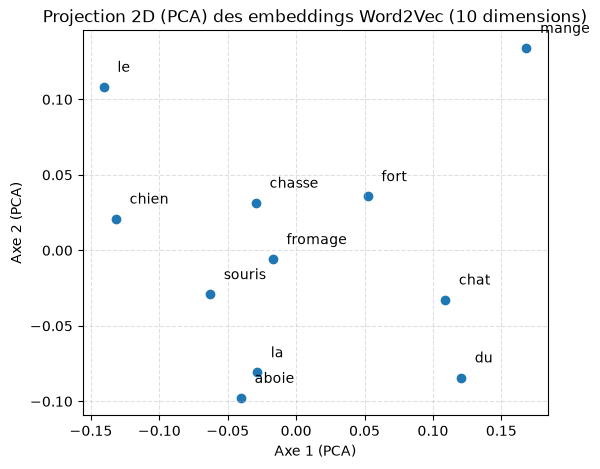

In [18]:
# !pip install -q scikit-learn
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

# --- Récupération des vecteurs correspondants ---
X = np.array([w2v_small.wv[w] for w in words])

# --- Réduction de dimension (PCA) ---
pca = PCA(n_components=2)
X2 = pca.fit_transform(X)

# --- Visualisation PCA ---
plt.figure(figsize=(6, 5))
plt.scatter(X2[:, 0], X2[:, 1])

for i, w in enumerate(words):
    plt.annotate(w, (X2[i, 0] + 0.01, X2[i, 1] + 0.01))

plt.title("Projection 2D (PCA) des embeddings Word2Vec (10 dimensions)")
plt.xlabel("Axe 1 (PCA)")
plt.ylabel("Axe 2 (PCA)")
plt.grid(True, linestyle="--", alpha=0.4)
plt.show()




### 💭 Question — Visualisation PCA des vecteurs Word2Vec

Observez la projection **PCA** de vos vecteurs Word2Vec dans le plan 2D.

1. Quels **groupes de mots** semblent se former dans la visualisation ?  
   - Certains mots apparaissent-ils plus proches les uns des autres ?  
   - Ces proximités sont-elles cohérentes avec le contenu de votre corpus ?

2. Peut-on **interpréter le sens des axes** du plan (axe 1 et axe 2) ?  
   - Correspondent-ils à des catégories sémantiques (ex. “animaux”, “actions”)  
     ou à des **combinaisons statistiques** sans signification explicite ?

3. **Modifiez le corpus** (en ajoutant de nouvelles phrases) puis **réentraînez le modèle**  
   -  Parvenez-vous à modifier la **position des mots** ?  Si oui, expliquez comment. 

- 1
    - on voit que "chien", "chasse" et "fort" se trouvent à peu près tous dans le même axe y=0.3 environ. On n'identifie rien d'autre de concret.
    - C'est cohérent avec le corpus puisque ces mots ont un lien avec le chien. Pour le reste, on ne voit pas de regroupement particulier.

- 2
    - cela semble être une combinaison statistique sans signification explicite. On ne peut pas dire que l'axe 1 ou l'axe 2 correspond à une catégorie sémantique particulière.
- 3


In [19]:
corpus_3 = [
    "le chat mange la souris",
    "le chat joue avec une balle",
    "le chat dort sur le canapé",
    "le chat aime manger des croquettes",
    "le chien chasse le chat",
    "le chien aboie fort",
    "le chien joue avec le chat",
    "le chien mange des croquettes",
    "la souris mange du fromage",
    "la souris se cache dans la maison",
    "le chat et le chien mangent des croquettes",
    "le chat et le chien jouent dans le jardin",
    "la souris fuit quand le chien aboie",
    "le chien regarde le chat",
    "le chat regarde la souris"
]
# tokenisation simple
sentences_3 = [s.split() for s in corpus_3]
w2v_small_3 = Word2Vec(sentences_3, vector_size=10, window=2, min_count=1, sg=1, epochs=200)

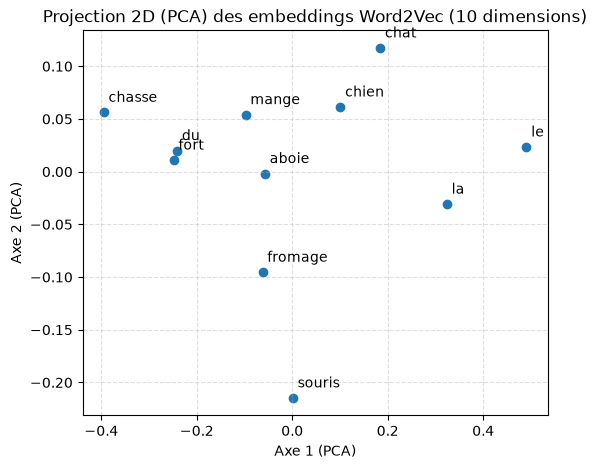

In [20]:
# !pip install -q scikit-learn
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

# --- Récupération des vecteurs correspondants ---
X = np.array([w2v_small_3.wv[w] for w in words])

# --- Réduction de dimension (PCA) ---
pca = PCA(n_components=2)
X2 = pca.fit_transform(X)

# --- Visualisation PCA ---
plt.figure(figsize=(6, 5))
plt.scatter(X2[:, 0], X2[:, 1])

for i, w in enumerate(words):
    plt.annotate(w, (X2[i, 0] + 0.01, X2[i, 1] + 0.01))

plt.title("Projection 2D (PCA) des embeddings Word2Vec (10 dimensions)")
plt.xlabel("Axe 1 (PCA)")
plt.ylabel("Axe 2 (PCA)")
plt.grid(True, linestyle="--", alpha=0.4)
plt.show()


- 3 suite 
    - On distingue maintenant mieux les groupes de mots dans ce pca : les déterminants sont en haut à droite, les verbes et adjectifs en haut à gauche, les sujets en haut, la souris et le fromage plus bas. 


### A.2 — Modèle **FastText** (corpus jouet) 

Contrairement à Word2Vec, FastText représente les mots à partir de leurs sous-unités (n-grams de caractères), ce qui permet de gérer les formes fléchies (variations grammaticales d'un mot: genre, nombre, conjugaison, superlatif, ...) et même certains mots inconnus.
Vous allez tester ce modèle sur le même corpus avec des paramètres semblables pour comparer avec Word2Vec.  

### 1 — Entrainez un modèle fastText sur le même corpus que Word2Vec avec les mêmes paramètres  
-  Recherchez les 5 voisins de chat  
-  Calculez la similarité cosinus (chat, chien) 

In [ ]:

#A COMPLETER
# #   Entraînez FastText
ft_model = FastText(.....)

# affichez les 5 plus proches  voisins de "chat"

# affichez la similarité cosinus (chat,chien)


### 💭 Questions
- Comparez les résultats obtenus avec ceux obtenus avec Word2Vec.

- Quelles différences remarquez-vous ? Comment les expliquez vous?


### 2 —  Recherches les voisins d'un **mot non présent dans le vocabulaire initial** (ex. `chats`, `chienne`) 


In [ ]:

# A COMPLETER
#   tentez d'afficher les 5 voisins d'un mot non vu (ex. "chats") avec FastText

#   tentez d'afficher les 5 voisins d'un mot non vu (ex. "chats")  Word2Vec 

### 💭 Questions
- Quelles différences remarquez-vous ?

- Comment expliquez-vous ce résultat


---
# Partie B — Utiliser un modèle FastText pré‑entraîné (réduit)

But : explorer similarité & analogies sur un grand vocabulaire.

- En pratique, on utilise souvent des **embeddings pré-entraînés** sur de très grands corpus.  
- Ici : vecteurs **FastText** de Facebook/Meta, entraînés sur *Common Crawl*.  
- Fichier original (≈1,3 Go) : [cc.fr.300.vec.gz](https://dl.fbaipublicfiles.com/fasttext/vectors-crawl/cc.fr.300.vec.gz)  
- Pour ce TP : **version réduite** à **100 000 mots** → fichiers à récupérer sur Teams (`cc.fr.100k.kv`et `cc.fr.100k.kv.vectors.npy` 
  - Plus léger (~150 Mo)  
  - Chargement rapide  
  - Suffisant pour vos expériences


### B.1 — Similarité & voisins


### 1 — Chargez un modèle fastText pré-entrainé 

In [ ]:

# !pip install -q gensim gensim-downloader

# from pathlib import Path
# from gensim.models import KeyedVectors


def load_pretrained(fr_kv="cc.fr.100k.kv"):
    """
    Charge uniquement le modèle réduit local (100k mots en français).
    Nécessite les fichiers :
      - cc.fr.100k.kv
      - cc.fr.100k.kv.vectors.npy
    dans le même dossier que ce notebook.
    """
    if Path(fr_kv).exists():
        m = KeyedVectors.load(fr_kv)
        return m, "FR_reduit_kv (local)"
    else:
        raise FileNotFoundError(
            f"Fichier {fr_kv} introuvable. "
            "👉 Vérifiez que cc.fr.100k.kv et cc.fr.100k.kv.vectors.npy "
            "sont dans le même dossier que le notebook."
        )

# Chargement du modèle réduit
MODEL, SOURCE = load_pretrained("cc.fr.100k.kv")

print("Modèle chargé depuis :", SOURCE)
print("Dimension des vecteurs :", MODEL.vector_size)
print("Taille vocab :", len(MODEL.key_to_index))


### 2 — Recherchez et affichez les 5 plus proches voisins de `chat` et la similarité sémantique (chat,chien)
Que remarquez vous ? 

In [ ]:
#A COMPLETER

# affichez les 5 plus proches  voisins de "chat"

# affichez la similarité cosinus (chat,chien)


### 3 — Calculez les similarités cosinus :  `(roi, reine)`, `(roi, président)`, `(roi, château)`  
→ Notez les scores & proposez une interprétation 


In [ ]:

#   calculs similarités cosinus



### B.2 — Analogies 
Une formule vectorielle (motA − motB + motC) est utile quand on veut trouver un mot dans la même relation que celle observée entre deux autres mots.  
Cela permet de répondre aux questions du type: Quels mots sont à C ce que A est à B?  <BR><BR>
  *Remarque* : Si l'on veut simplement voir quels mots sont proches de 'roi'', on utilise directement most_similar("roi"), pas une formule.  
  
  ### 1 —  Testez l'analogie `roi − homme + femme`  
   
→ A quelle question implicite cela permet-il de répondre ?  
→ Interprétez le résultat



In [ ]:

#   `roi − homme + femme` 
MODEL.most_similar(positive=["roi","femme"], negative=["homme"], topn=10)    


### 2 —  Recherche par analogie  
  
  On souhaite rechercher la capitale de l'Italie  
  
→ Essayez most_similar("Italie") → que remarquez-vous ?  
→ Reformulez la question avec une  analogie utilisant la capitale de la France  
→ Commentez le résultat


In [ ]:
#   A COMPLETER
   


### 3 — Analogies et polysémie :  Testez le mot batterie.

Quels sont ses 10 voisins les plus proches ?

Voyez-vous plusieurs sens mélangés ?

In [ ]:
#   A COMPLETER

### 4 — Calculez les similarités Cosinus avec MODEL.similarity(mot1, mot2) pour comparer les similarités entre 'batterie' et :  
- des mots du champ **musical** : `percussion`, `orchestre`, `musique`  
- des mots du champ **énergie** : `énergie`, `smartphone`, `recharge`  <BR>Qu’observez-vous ? 

In [ ]:

# A COMPLETER


### 5 — Calculez et comparez les **distances cosinus** (MODEL.distances(mot1, [m1, m2, ...]) entre `avion` et deux groupes de mots :  

- Groupe **transport aérien** : `vol`, `aéroport`, `pilote`  
- Groupe **jeu / papier plié** : `jouet`, `pliage`, `papier`  
 
- Quels sont les scores obtenus pour chaque groupe ?  
- Quelle interprétation peut-on faire de la différence entre les deux ?  


In [ ]:
# A COMPLETER



### 6 - Identifiez et expliquez la limite des embeddings statiques mise en évidence dans les questions précédentes   
Observe-t-on un mélange de sens ?
